# 01 - MIT-BIH ECG Data Exploration

### 1.1. Objective

This notebook explores the MIT-BIH Arrhythmia Database and verifies that the ECG signals and expert heartbeat annotations can be loaded correctly.

### Goals

1. Define project paths.
2. Download the MIT-BIH Arrhythmia Database.
3. Load one ECG recording.
4. Inspect ECG metadata.
5. Read expert heartbeat annotations.
6. Visualize ECG signals and annotated beats.
7. Examine heartbeat class distributions.

The MIT-BIH database will be used as the source dataset for developing an ECG heartbeat classification model.

In [1]:
# ============================================================
# SECTION 1: IMPORT LIBRARIES
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb


# ============================================================
# SECTION 2: FIND PROJECT ROOT
# ============================================================

# Start from the current working directory.
CURRENT_DIR = Path.cwd().resolve()

# Search upward until we find the ECG-ML project root.
# We identify the project root using requirements.txt.

PROJECT_ROOT = CURRENT_DIR

while not (PROJECT_ROOT / "requirements.txt").exists():

    # Stop if we reach the top of the filesystem.
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Could not locate the ECG-ML project root."
        )

    PROJECT_ROOT = PROJECT_ROOT.parent


# ============================================================
# SECTION 3: DEFINE DATA DIRECTORIES
# ============================================================

# Main data directory
DATA_DIR = PROJECT_ROOT / "data"

# Original, untouched ECG datasets
RAW_DATA_DIR = DATA_DIR / "raw"

# MIT-BIH Arrhythmia Database
MITDB_DIR = RAW_DATA_DIR / "mitdb"

# Processed ECG data
PROCESSED_DATA_DIR = DATA_DIR / "processed"


# ============================================================
# SECTION 4: DEFINE OTHER PROJECT DIRECTORIES
# ============================================================

# Results
RESULTS_DIR = PROJECT_ROOT / "results"

# Figures generated during analysis
FIGURES_DIR = RESULTS_DIR / "figures"

# Model evaluation metrics
METRICS_DIR = RESULTS_DIR / "metrics"

# Saved ML and deep-learning models
MODELS_DIR = PROJECT_ROOT / "models"


# ============================================================
# SECTION 5: CREATE DIRECTORIES
# ============================================================

DATA_DIR.mkdir(parents=True, exist_ok=True)
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
MITDB_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

MODELS_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# SECTION 6: VERIFY PROJECT PATHS
# ============================================================

print("Project root:   ", PROJECT_ROOT)
print("Data:           ", DATA_DIR)
print("Raw data:       ", RAW_DATA_DIR)
print("MIT-BIH data:   ", MITDB_DIR)
print("Processed data: ", PROCESSED_DATA_DIR)
print("Figures:        ", FIGURES_DIR)
print("Metrics:        ", METRICS_DIR)
print("Models:         ", MODELS_DIR)

Project root:    /Users/janusaban/Documents/ML_research/04_ecg-ml
Data:            /Users/janusaban/Documents/ML_research/04_ecg-ml/data
Raw data:        /Users/janusaban/Documents/ML_research/04_ecg-ml/data/raw
MIT-BIH data:    /Users/janusaban/Documents/ML_research/04_ecg-ml/data/raw/mitdb
Processed data:  /Users/janusaban/Documents/ML_research/04_ecg-ml/data/processed
Figures:         /Users/janusaban/Documents/ML_research/04_ecg-ml/results/figures
Metrics:         /Users/janusaban/Documents/ML_research/04_ecg-ml/results/metrics
Models:          /Users/janusaban/Documents/ML_research/04_ecg-ml/models


### 1.2. Download the MIT-BIH Arrhythmia Database

The dataset will be downloaded directly from PhysioNet using the `wfdb` Python package.

The original files will be stored in:

`data/raw/mitdb/`

The raw dataset will not be modified during preprocessing. All derived datasets will be saved separately under `data/processed/`.

In [2]:
# ============================================================
# DOWNLOAD MIT-BIH DATABASE
# ============================================================

# Check whether record 100 already exists.
# This prevents the entire dataset from being downloaded
# repeatedly every time the notebook is executed.

record_100_header = RAW_DATA_DIR / "100.hea"

if not record_100_header.exists():
    
    print("Downloading MIT-BIH Arrhythmia Database...")
    
    wfdb.dl_database(
        db_dir="mitdb",
        dl_dir=str(RAW_DATA_DIR)
    )
    
    print("Download complete.")

else:
    
    print("MIT-BIH database already exists.")

MIT-BIH database already exists.


### 1.3. Inspect the downloaded database

Each MIT-BIH ECG recording consists of multiple files.

For example, record `100` includes:

- `100.dat` - raw ECG waveform
- `100.hea` - signal metadata and header information
- `100.atr` - expert heartbeat annotations

The annotations provide the locations and types of beats identified by expert reviewers.

In [3]:
# ============================================================
# INSPECT DOWNLOADED FILES
# ============================================================

files = sorted(RAW_DATA_DIR.iterdir())

print(f"Number of files: {len(files)}")
print("\nFirst 20 files:")

for file in files[:20]:
    print(file.name)

Number of files: 145

First 20 files:
100.atr
100.dat
100.hea
101.atr
101.dat
101.hea
102.atr
102.dat
102.hea
103.atr
103.dat
103.hea
104.atr
104.dat
104.hea
105.atr
105.dat
105.hea
106.atr
106.dat


### 1.4. Load ECG Record 100

Record `100` will be used as an initial example.

We will inspect:

- Sampling frequency
- Number of samples
- ECG channels
- Signal duration

In [4]:
# ============================================================
# LOAD ECG RECORD 100
# ============================================================

record_name = "100"
record_path = RAW_DATA_DIR / record_name

record = wfdb.rdrecord(str(record_path))


# ============================================================
# EXTRACT ECG INFORMATION
# ============================================================

ecg_signal = record.p_signal
sampling_frequency = record.fs
signal_names = record.sig_name

duration_seconds = len(ecg_signal) / sampling_frequency


# ============================================================
# DISPLAY INFORMATION
# ============================================================

print("Record:", record_name)
print("Sampling frequency:", sampling_frequency, "Hz")
print("Number of samples:", len(ecg_signal))
print("Number of ECG channels:", ecg_signal.shape[1])
print("Signal names:", signal_names)
print("Duration:", duration_seconds / 60, "minutes")

Record: 100
Sampling frequency: 360 Hz
Number of samples: 650000
Number of ECG channels: 2
Signal names: ['MLII', 'V5']
Duration: 30.092592592592595 minutes


### 1.5. Visualize a Short ECG Segment

Plotting a short segment makes the ECG morphology easier to inspect.

For this initial visualization, the first 10 seconds of the first ECG channel will be displayed.

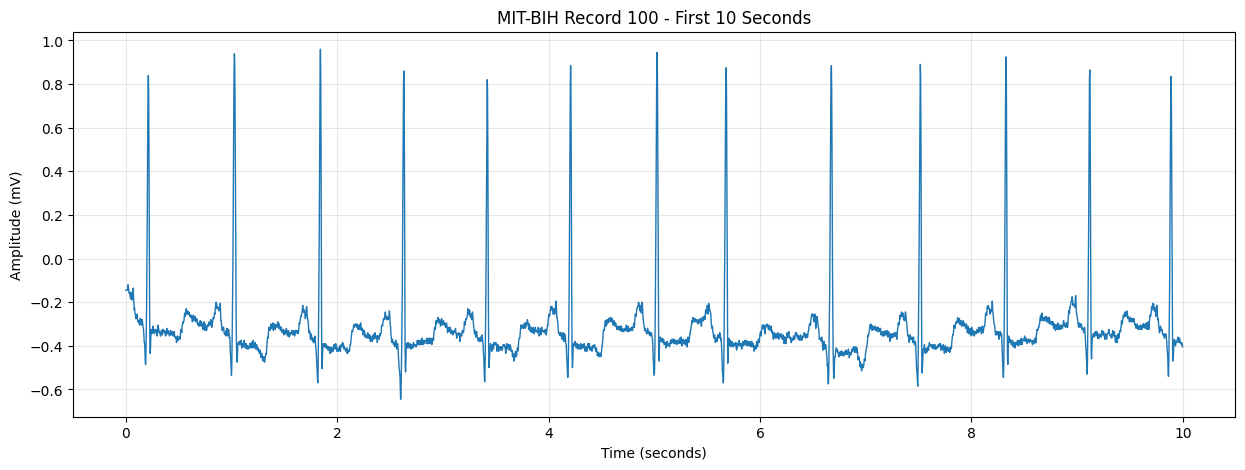

In [5]:
# ============================================================
# SELECT ECG CHANNEL
# ============================================================

channel = 0

signal = ecg_signal[:, channel]


# ============================================================
# SELECT FIRST 10 SECONDS
# ============================================================

duration_to_plot = 10

samples_to_plot = int(duration_to_plot * sampling_frequency)

time = np.arange(samples_to_plot) / sampling_frequency


# ============================================================
# PLOT ECG
# ============================================================

plt.figure(figsize=(15, 5))

plt.plot(
    time,
    signal[:samples_to_plot],
    linewidth=1
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title(f"MIT-BIH Record {record_name} - First 10 Seconds")
plt.grid(alpha=0.3)

plt.show()

### 1.6. Load Heartbeat Annotations

MIT-BIH provides expert annotations identifying heartbeat locations and beat types.

Important annotation information includes:

- `sample`: position of the heartbeat in the ECG signal
- `symbol`: annotation describing the heartbeat type

These labels will later become the ground-truth targets for machine learning.

In [6]:
# ============================================================
# LOAD EXPERT ANNOTATIONS
# ============================================================

annotation = wfdb.rdann(
    str(record_path),
    "atr"
)


# ============================================================
# INSPECT ANNOTATIONS
# ============================================================

print("Number of annotations:", len(annotation.sample))

print("\nFirst 20 annotation samples:")
print(annotation.sample[:20])

print("\nFirst 20 annotation symbols:")
print(annotation.symbol[:20])

Number of annotations: 2274

First 20 annotation samples:
[  18   77  370  662  946 1231 1515 1809 2044 2402 2706 2998 3282 3560
 3862 4170 4466 4764 5060 5346]

First 20 annotation symbols:
['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


### 1.7. Visualize Expert-Annotated Beats

The expert annotation locations will now be overlaid on the ECG waveform.

This verifies that the annotations correspond to heartbeat locations before they are used for machine learning.

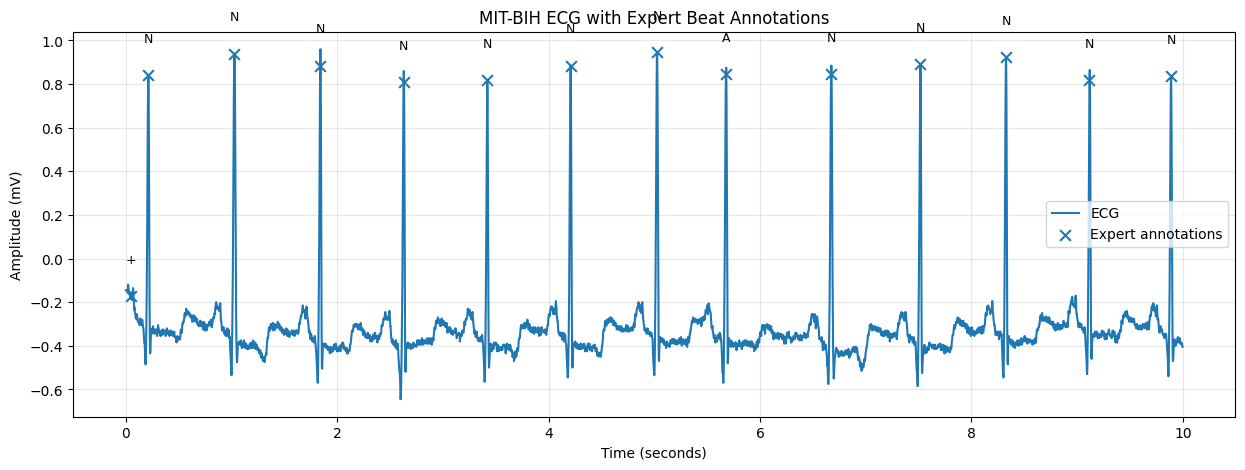

In [7]:
# ============================================================
# SELECT ANNOTATIONS WITHIN FIRST 10 SECONDS
# ============================================================

annotation_mask = annotation.sample < samples_to_plot

annotation_samples = annotation.sample[annotation_mask]
annotation_symbols = np.array(annotation.symbol)[annotation_mask]


# ============================================================
# CONVERT SAMPLE POSITIONS TO TIME
# ============================================================

annotation_times = annotation_samples / sampling_frequency


# ============================================================
# PLOT ECG WITH ANNOTATIONS
# ============================================================

plt.figure(figsize=(15, 5))

plt.plot(
    time,
    signal[:samples_to_plot],
    label="ECG"
)

plt.scatter(
    annotation_times,
    signal[annotation_samples],
    marker="x",
    s=60,
    label="Expert annotations"
)


# ============================================================
# DISPLAY BEAT SYMBOLS
# ============================================================

for x, sample, symbol in zip(
    annotation_times,
    annotation_samples,
    annotation_symbols
):
    
    plt.text(
        x,
        signal[sample] + 0.15,
        symbol,
        fontsize=9,
        ha="center"
    )


plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.title("MIT-BIH ECG with Expert Beat Annotations")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### 1.8. Heartbeat Annotation Distribution

MIT-BIH contains several detailed beat annotation types.

Later, these detailed annotations will be mapped into broader AAMI heartbeat categories to create a more manageable and clinically meaningful classification problem.

In [8]:
# ============================================================
# COUNT ANNOTATION SYMBOLS
# ============================================================

annotation_counts = (
    pd.Series(annotation.symbol)
    .value_counts()
    .sort_values(ascending=False)
)


# ============================================================
# DISPLAY COUNTS
# ============================================================

display(annotation_counts.to_frame("count"))

,count
N,2239
A,33
+,1
V,1
